# Member 1 — Clustering Track: Evaluation and Visualisation (Gas Sensor Array Drift)

**Review 2 scope (Member 1):** clustering deliverables **B2** (Silhouette, Davies-Bouldin and Calinski-Harabasz
for every algorithm, Elbow curve for K-Means, Dendrogram for Hierarchical clustering) and **B3** (PCA 2-D scatter
plot for every algorithm, t-SNE plot).

- Dataset: UCI *Gas Sensor Array Drift at Different Concentrations* — 13,910 measurements, 128 features
  (16 chemical sensors x 8 features each), 6 gases.
- Clustering is unsupervised: the gas label (`class`) and `concentration` are **removed before fitting** and used
  only afterwards to interpret the clusters.
- `random_state=42` everywhere. Every plot has a title, labelled axes and a legend; palettes are colour-blind safe.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', palette='colorblind')
os.environ['PYTHONWARNINGS'] = 'ignore::UserWarning'
warnings.filterwarnings('ignore', category=UserWarning)

RESULTS_DIR = Path('../results/clustering')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / name, dpi=150, bbox_inches='tight')

## 1. Load data and build the feature matrix

The raw data is the ten `batch*.dat` files converted to one CSV by `data/raw/gassensor/convert_gas_sensor.py`.

In [2]:
df = pd.read_csv('../data/raw/gassensor/gas_sensor/gas_sensor.csv')
GAS_NAMES = {1: 'Ethanol', 2: 'Ethylene', 3: 'Ammonia', 4: 'Acetaldehyde', 5: 'Acetone', 6: 'Toluene'}

y_gas = df['class'].map(GAS_NAMES)            # kept aside, used only for interpretation
X_raw = df.drop(columns=['class', 'concentration'])

print('shape:', df.shape, '| features used for clustering:', X_raw.shape[1])
print('missing values:', int(df.isna().sum().sum()), '| duplicate rows:', int(df.duplicated().sum()))
skew = X_raw.skew().abs()
print('median |skewness| of the features: %.1f | features with |skewness| > 5: %d' % (skew.median(), (skew > 5).sum()))
display(y_gas.value_counts().rename('measurements').to_frame())

shape: (13910, 130) | features used for clustering: 128
missing values: 0 | duplicate rows: 0
median |skewness| of the features: 2.4 | features with |skewness| > 5: 36


,measurements
class,
Acetone,3009
Ethylene,2926
Ethanol,2565
Acetaldehyde,1936
Toluene,1833
Ammonia,1641


### 1.1 Scaling

Two steps, both justified by the data:
1. **Signed log transform** `sign(x) * log1p(|x|)`. The features mix raw resistance changes in the tens of
   thousands with small transient slopes, many of them negative and heavily skewed. The signed log keeps the sign
   and compresses the long tails, so a handful of extreme readings do not dominate the distances.
2. **`StandardScaler`** so each of the 128 features has mean 0 and variance 1. K-Means and Ward linkage use
   Euclidean distance; without scaling the resistance features (~10^4) would decide every cluster on their own.

There is no train/test split in clustering, so the scaler is fitted on the whole feature matrix. No label
information enters this step.

In [3]:
X_log = np.sign(X_raw) * np.log1p(X_raw.abs())
X = StandardScaler().fit_transform(X_log)
print('scaled matrix:', X.shape, '| max |skewness| before: %.1f, after signed log: %.1f'
      % (X_raw.skew().abs().max(), X_log.skew().abs().max()))

scaled matrix: (13910, 128) | max |skewness| before: 117.9, after signed log: 6.2


In [4]:
def cluster_scores(X, labels):
    """The three internal metrics required for every algorithm."""
    return {
        'n_clusters': len(np.unique(labels)),
        'silhouette': silhouette_score(X, labels, random_state=RANDOM_STATE),
        'davies_bouldin': davies_bouldin_score(X, labels),
        'calinski_harabasz': calinski_harabasz_score(X, labels),
    }

## 2. K-Means: Elbow curve (B2)

K-Means is fitted for k = 2 ... 10 (`n_init=10`). The **Elbow curve** plots inertia (within-cluster sum of squared
distances) against k: inertia always falls as k grows, so the useful k is where the curve bends and extra clusters
stop paying off. The bend is located with the *maximum distance to the chord* rule (the point furthest from the
straight line joining the first and last points), and the silhouette score is plotted next to it as a second opinion.

In [5]:
K_RANGE = range(2, 11)
elbow_rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    elbow_rows.append({'k': k, 'inertia': km.inertia_,
                       'silhouette': silhouette_score(X, km.labels_, random_state=RANDOM_STATE)})
elbow = pd.DataFrame(elbow_rows).set_index('k')

def elbow_point(x, y):
    """Index of the point furthest from the chord joining the first and last points."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    xn, yn = (x - x[0]) / (x[-1] - x[0]), (y - y[-1]) / (y[0] - y[-1])
    return int(np.argmax(np.abs(yn - (1 - xn))))

K_BEST = int(elbow.index[elbow_point(elbow.index, elbow['inertia'])])
print('elbow at k =', K_BEST)
display(elbow.round(3))

elbow at k = 4


,inertia,silhouette
k,,
2,1057752.083,0.345
3,875096.844,0.320
4,729789.783,0.267
5,662613.702,0.229
6,609723.003,0.250
7,564912.178,0.233
8,523216.601,0.224
9,497447.492,0.210
10,473073.692,0.211


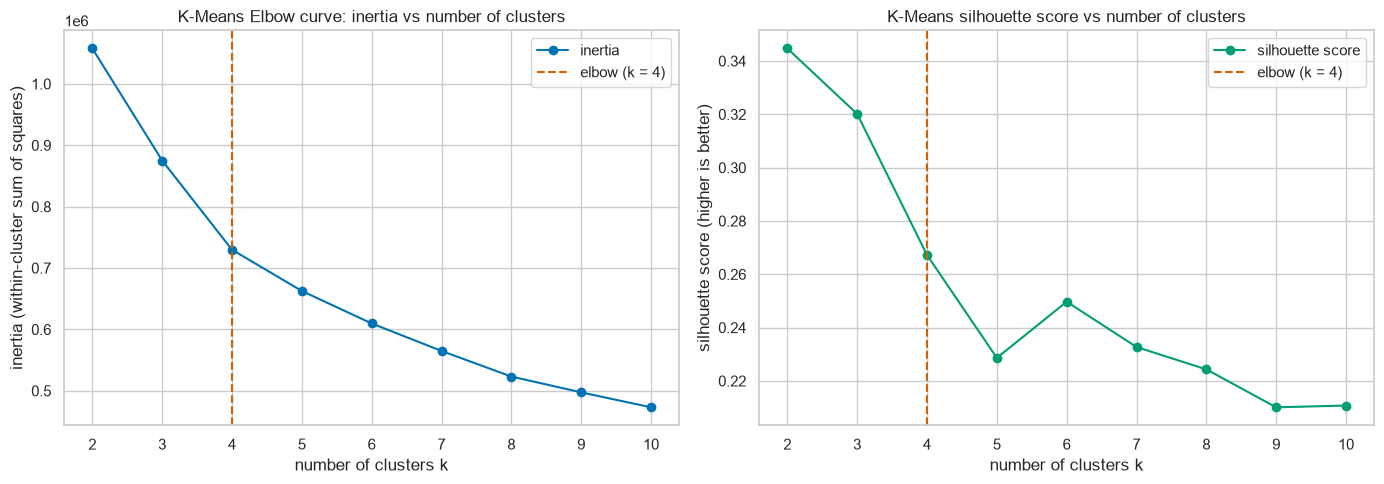

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(elbow.index, elbow['inertia'], marker='o', label='inertia')
axes[0].axvline(K_BEST, color='C3', ls='--', label=f'elbow (k = {K_BEST})')
axes[0].set_title('K-Means Elbow curve: inertia vs number of clusters')
axes[0].set_xlabel('number of clusters k')
axes[0].set_ylabel('inertia (within-cluster sum of squares)')
axes[0].legend()

axes[1].plot(elbow.index, elbow['silhouette'], marker='o', color='C2', label='silhouette score')
axes[1].axvline(K_BEST, color='C3', ls='--', label=f'elbow (k = {K_BEST})')
axes[1].set_title('K-Means silhouette score vs number of clusters')
axes[1].set_xlabel('number of clusters k')
axes[1].set_ylabel('silhouette score (higher is better)')
axes[1].legend()
save_fig('kmeans_elbow_silhouette.png')
plt.show()

**Observation.**
- Inertia drops fast up to k = 4 (1.06M -> 0.73M) and then falls in smaller, nearly even steps (0.73M -> 0.47M over
  six more clusters). The chord rule puts the elbow at **k = 4**.
- Silhouette is highest at k = 2 (0.345) and keeps falling, with a small bump at k = 6 (0.250). A high k = 2 silhouette
  is common: splitting into two big halves is easy, but it says little about the data's finer structure.
- k = 4 is used for both algorithms. It is where adding clusters stops paying off in inertia, and its silhouette
  (0.267) is still well above the k >= 7 values.

In [7]:
kmeans = KMeans(n_clusters=K_BEST, n_init=10, random_state=RANDOM_STATE).fit(X)
labels = {'K-Means': kmeans.labels_}
print('K-Means cluster sizes:', np.bincount(kmeans.labels_).tolist())

K-Means cluster sizes: [4653, 3766, 2486, 3005]


## 3. Hierarchical clustering: Dendrogram and linkage strategies (B2)

Agglomerative clustering starts with every measurement as its own cluster and repeatedly merges the closest pair.
*Closest* depends on the **linkage**:
- **ward** — merge that increases total within-cluster variance the least (same objective as K-Means);
- **complete** — distance between the two farthest members;
- **average** — mean distance between all pairs;
- **single** — distance between the two nearest members (prone to *chaining*).

### 3.1 Dendrogram

The Ward linkage tree is computed on all 13,910 rows with SciPy. Drawing 13,910 leaves is unreadable, so the plot
is truncated to the last 40 merges (`truncate_mode='lastp'`); leaf labels in brackets give how many measurements
sit under that branch. The vertical axis is the merge distance, so long vertical gaps mark natural cut points.

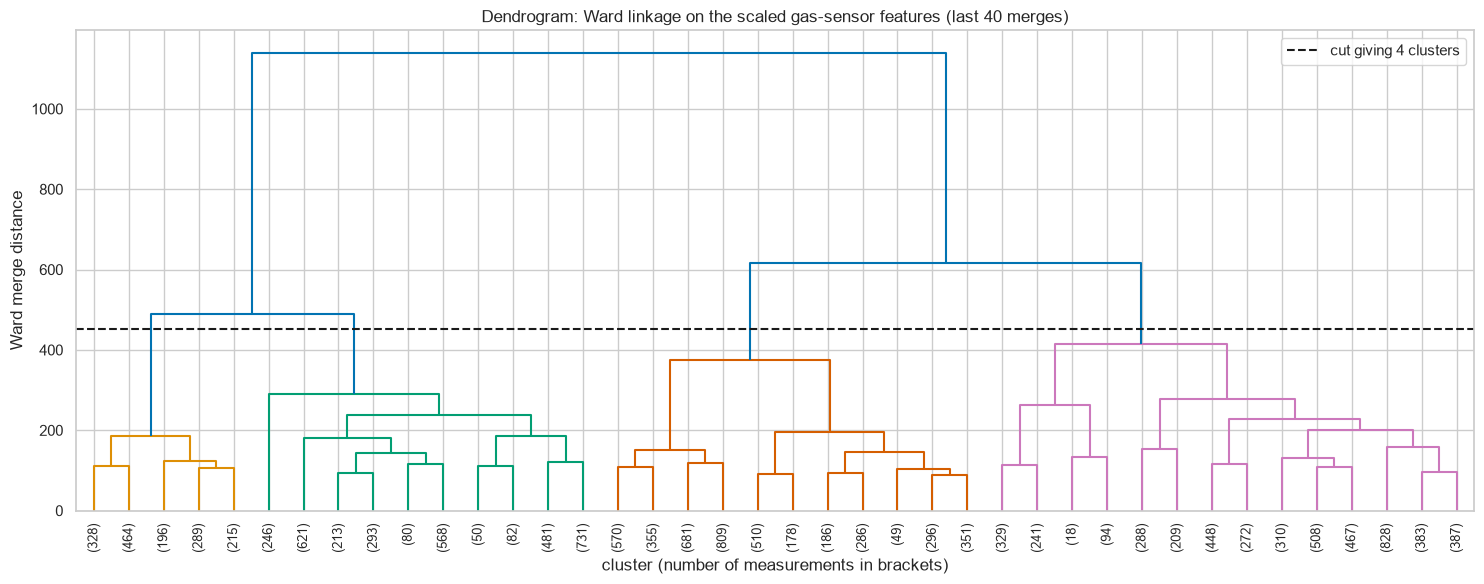

largest 10 merge distances (top of the tree): [1138.1, 616.8, 488.7, 413.7, 373.8, 290.3, 276.8, 263.2, 237.5, 227.1]
gap between successive merges: [521.3, 128.1, 75.0, 39.9, 83.5, 13.5, 13.6, 25.8, 10.3]


In [8]:
Z_ward = linkage(X, method='ward')

fig, ax = plt.subplots(figsize=(15, 6))
dendrogram(Z_ward, truncate_mode='lastp', p=40, show_leaf_counts=True, leaf_rotation=90,
           leaf_font_size=9, color_threshold=Z_ward[-(K_BEST - 1), 2], ax=ax)
cut = (Z_ward[-K_BEST, 2] + Z_ward[-(K_BEST - 1), 2]) / 2
ax.axhline(cut, color='k', ls='--', label=f'cut giving {K_BEST} clusters')
ax.set_title('Dendrogram: Ward linkage on the scaled gas-sensor features (last 40 merges)')
ax.set_xlabel('cluster (number of measurements in brackets)')
ax.set_ylabel('Ward merge distance')
ax.legend(loc='upper right')
save_fig('hierarchical_dendrogram_ward.png')
plt.show()

last = Z_ward[-10:, 2][::-1]
print('largest 10 merge distances (top of the tree):', np.round(last, 1).tolist())
print('gap between successive merges:', np.round(-np.diff(last), 1).tolist())

**Observation.**
- The top merge (distance 1138) is far above everything else, so the strongest split is into **two** groups — the
  same answer the silhouette gave at k = 2.
- Below it the merges at 617 and 489 are still clearly separated from the 414 merge underneath; the cut between 489
  and 414 (dashed line) gives **4 clusters**, agreeing with the K-Means elbow. Below ~400 the merge heights shrink
  steadily with no large gap, so cutting lower would split clusters without a clear natural boundary.

### 3.2 Comparing linkage strategies

Each linkage is cut at the same number of clusters (k from the elbow) so the comparison is fair. Cluster sizes are
shown because a high silhouette with one giant cluster and a few singletons is not a useful clustering.

In [9]:
link_rows, link_labels = [], {}
for method in ['ward', 'complete', 'average', 'single']:
    agg = AgglomerativeClustering(n_clusters=K_BEST, linkage=method).fit(X)
    link_labels[method] = agg.labels_
    sizes = np.sort(np.bincount(agg.labels_))[::-1]
    link_rows.append({'linkage': method, **cluster_scores(X, agg.labels_),
                      'largest cluster share': sizes[0] / len(X), 'cluster sizes': sizes.tolist()})
linkage_table = pd.DataFrame(link_rows).set_index('linkage')
display(linkage_table.round(3))
linkage_table.to_csv(RESULTS_DIR / 'linkage_comparison.csv')

,n_clusters,silhouette,davies_bouldin,calinski_harabasz,largest cluster share,cluster sizes
linkage,,,,,,
ward,4,0.202,1.378,5390.260,0.344,"[4782, 4271, 3365, 1492]"
complete,4,0.323,0.794,3297.964,0.625,"[8699, 5095, 115, 1]"
average,4,0.629,0.227,20.647,1.000,"[13907, 1, 1, 1]"
single,4,0.572,0.276,13.464,1.000,"[13907, 1, 1, 1]"


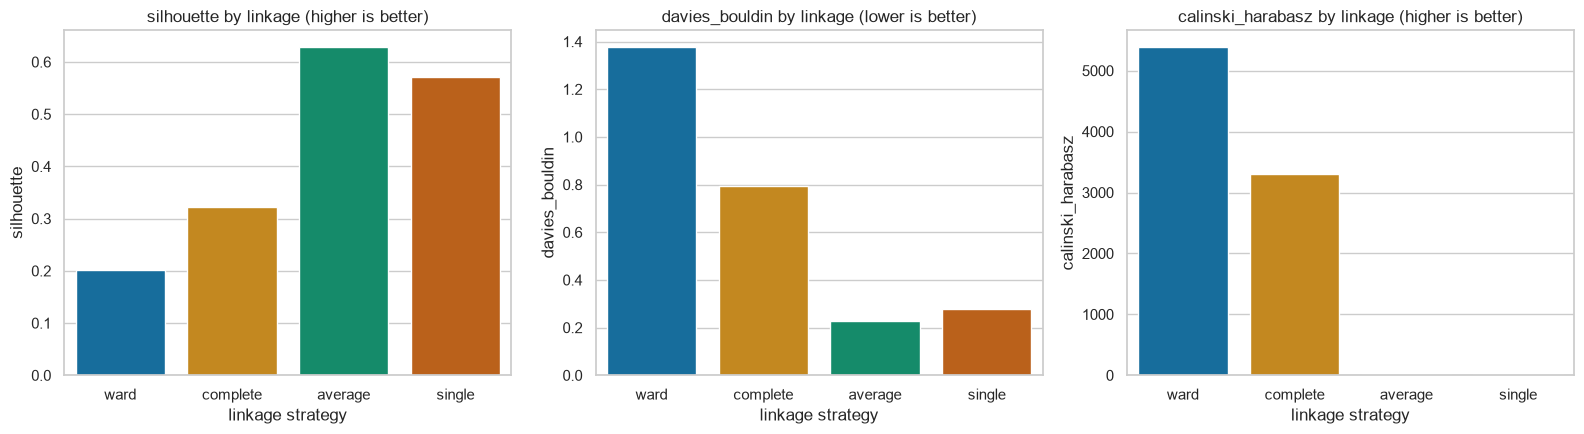

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric, better in zip(axes, ['silhouette', 'davies_bouldin', 'calinski_harabasz'],
                              ['higher is better', 'lower is better', 'higher is better']):
    sns.barplot(x=linkage_table.index, y=linkage_table[metric], hue=linkage_table.index, palette='colorblind',
                legend=False, ax=ax)
    ax.set_title(f'{metric} by linkage ({better})')
    ax.set_xlabel('linkage strategy')
    ax.set_ylabel(metric)
save_fig('linkage_comparison.png')
plt.show()

**Observation.**
- **Average** and **single** linkage have the best silhouette (0.63, 0.57) and Davies-Bouldin scores, but this is
  misleading: each puts 13,907 of 13,910 points in one cluster and leaves three outliers as singletons. Their
  Calinski-Harabasz scores (21 and 13) expose this. Single linkage *chains* through dense regions, and average
  linkage is pulled the same way by a few far-away readings.
- **Complete** linkage is better balanced but still has a 1-point and a 115-point cluster.
- **Ward** gives four usable clusters (34%, 31%, 24%, 11%) and by far the highest Calinski-Harabasz (5,390). It is
  kept as the hierarchical model. Lesson: internal metrics must be read together with the cluster sizes.

In [11]:
LINKAGE = 'ward'
labels['Agglomerative (ward)'] = link_labels[LINKAGE]
print('Agglomerative cluster sizes:', np.bincount(labels['Agglomerative (ward)']).tolist())

Agglomerative cluster sizes: [4782, 3365, 4271, 1492]


## 4. Evaluation metrics for both algorithms (B2)

| Metric | Measures | Better |
|---|---|---|
| Silhouette | how much closer each point is to its own cluster than to the next one (-1 ... 1) | higher |
| Davies-Bouldin | average similarity of each cluster to its most similar other cluster | lower |
| Calinski-Harabasz | between-cluster dispersion / within-cluster dispersion | higher |

All three use only the feature matrix and the cluster labels — no ground truth.

In [12]:
metrics_table = pd.DataFrame({name: cluster_scores(X, lab) for name, lab in labels.items()}).T
metrics_table.index.name = 'algorithm'
display(metrics_table.round(3))
metrics_table.to_csv(RESULTS_DIR / 'clustering_metrics.csv')

,n_clusters,silhouette,davies_bouldin,calinski_harabasz
algorithm,,,,
K-Means,4.0,0.267,1.253,6673.565
Agglomerative (ward),4.0,0.202,1.378,5390.260


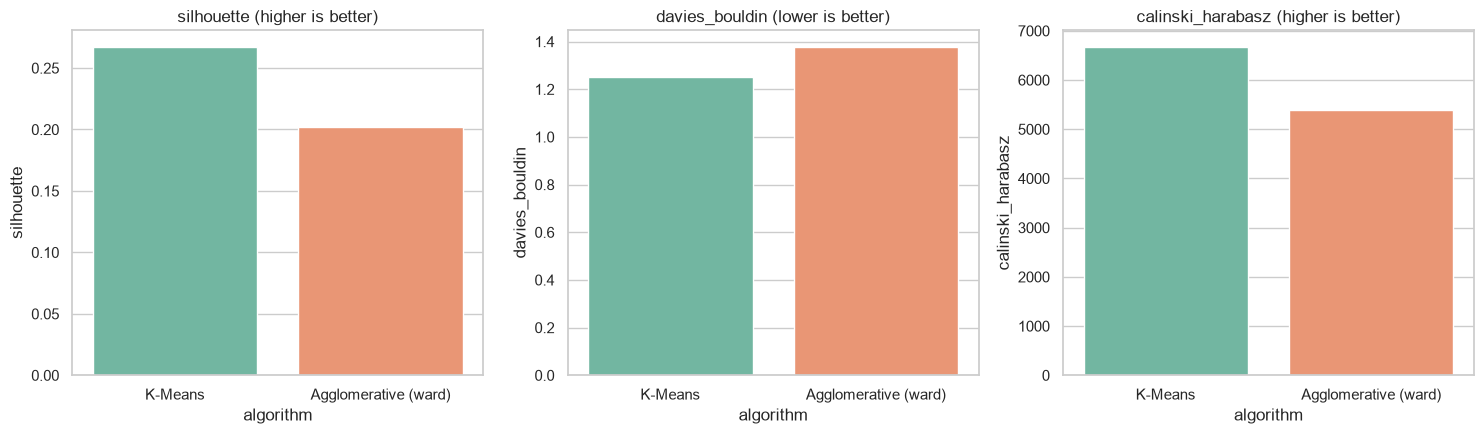

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, metric, better in zip(axes, ['silhouette', 'davies_bouldin', 'calinski_harabasz'],
                              ['higher is better', 'lower is better', 'higher is better']):
    sns.barplot(x=metrics_table.index, y=metrics_table[metric].astype(float), hue=metrics_table.index,
                palette='Set2', legend=False, ax=ax)
    ax.set_title(f'{metric} ({better})')
    ax.set_xlabel('algorithm')
    ax.set_ylabel(metric)
save_fig('clustering_metrics_comparison.png')
plt.show()

**Observation.** K-Means is better on all three metrics: silhouette 0.267 vs 0.202, Davies-Bouldin 1.25 vs 1.38,
Calinski-Harabasz 6,674 vs 5,390. This is expected: these metrics reward compact, roughly spherical clusters around
a centroid, which is exactly what K-Means optimises, whereas Ward makes greedy merges it can never undo.
Both silhouettes are low (0.2-0.3): the clusters overlap and are not sharply separated in 128-D.

## 5. PCA cluster visualisation (B3)

PCA projects the 128 scaled features onto the two directions of largest variance. It is used **only for plotting**:
the clusters were found in the full 128-dimensional space, so overlap in 2-D can hide separation that exists in
the other dimensions. The explained-variance ratio says how much of the structure the plot can show.

In [14]:
pca = PCA(random_state=RANDOM_STATE).fit(X)
X_pca = pca.transform(X)[:, :2]
cum = np.cumsum(pca.explained_variance_ratio_)
print('variance explained by PC1, PC2: %.3f, %.3f (together %.3f)'
      % (pca.explained_variance_ratio_[0], pca.explained_variance_ratio_[1], cum[1]))
print('components needed for 90%% / 95%% of the variance: %d / %d'
      % (np.searchsorted(cum, 0.90) + 1, np.searchsorted(cum, 0.95) + 1))

variance explained by PC1, PC2: 0.605, 0.168 (together 0.772)
components needed for 90% / 95% of the variance: 5 / 9


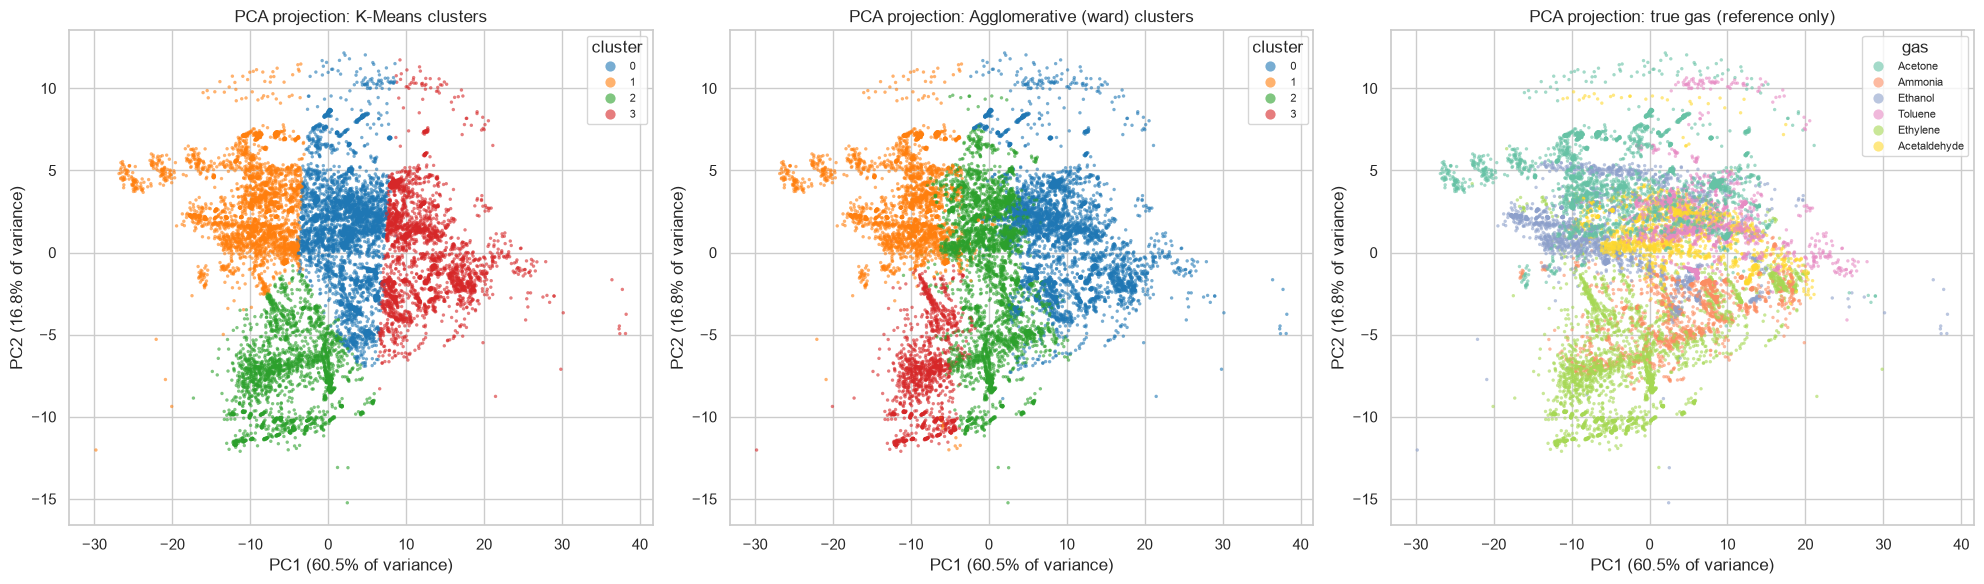

In [15]:
def scatter_2d(ax, coords, lab, title, xlabel, ylabel, palette='tab10'):
    """Colour-coded 2-D scatter of one labelling."""
    lab = pd.Series(lab).astype(str)
    order = sorted(lab.unique(), key=lambda s: (len(s), s))
    sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=lab, hue_order=order, palette=palette,
                    s=6, alpha=0.6, linewidth=0, ax=ax)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(title='cluster' if palette != 'Set2' else 'gas', markerscale=3, fontsize=8, loc='best')

pc_x = f'PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)'
pc_y = f'PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)'
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (name, lab) in zip(axes, labels.items()):
    scatter_2d(ax, X_pca, lab, f'PCA projection: {name} clusters', pc_x, pc_y)
scatter_2d(axes[2], X_pca, y_gas, 'PCA projection: true gas (reference only)', pc_x, pc_y, palette='Set2')
save_fig('pca_clusters.png')
plt.show()

**Observation.**
- The first two components explain **77%** of the variance (PC1 60.5%, PC2 16.8%), so the 2-D view is a fair summary;
  5 components reach 90%.
- K-Means cuts the cloud into four clean vertical / lower bands along PC1 and PC2 — its clusters are compact regions
  of feature space. Ward agrees on the left (orange) and lower (red) groups but splits the middle differently, so its
  boundaries cross the PCA view diagonally.
- In the reference panel the gases overlap heavily in PCA space. Only Ethylene (lower region) and part of Acetone /
  Ethanol (left) occupy their own area, which already suggests the clusters cannot match the six gases one-to-one.

## 6. t-SNE cluster visualisation (B3)

t-SNE is a non-linear embedding that keeps *local* neighbourhoods: points close in 128-D stay close in 2-D. It is
run on the first 30 principal components (standard practice: removes noise and makes t-SNE faster) with
`perplexity=40`. Distances *between* far-apart groups and the size of groups in a t-SNE plot are not meaningful,
only which points sit together.

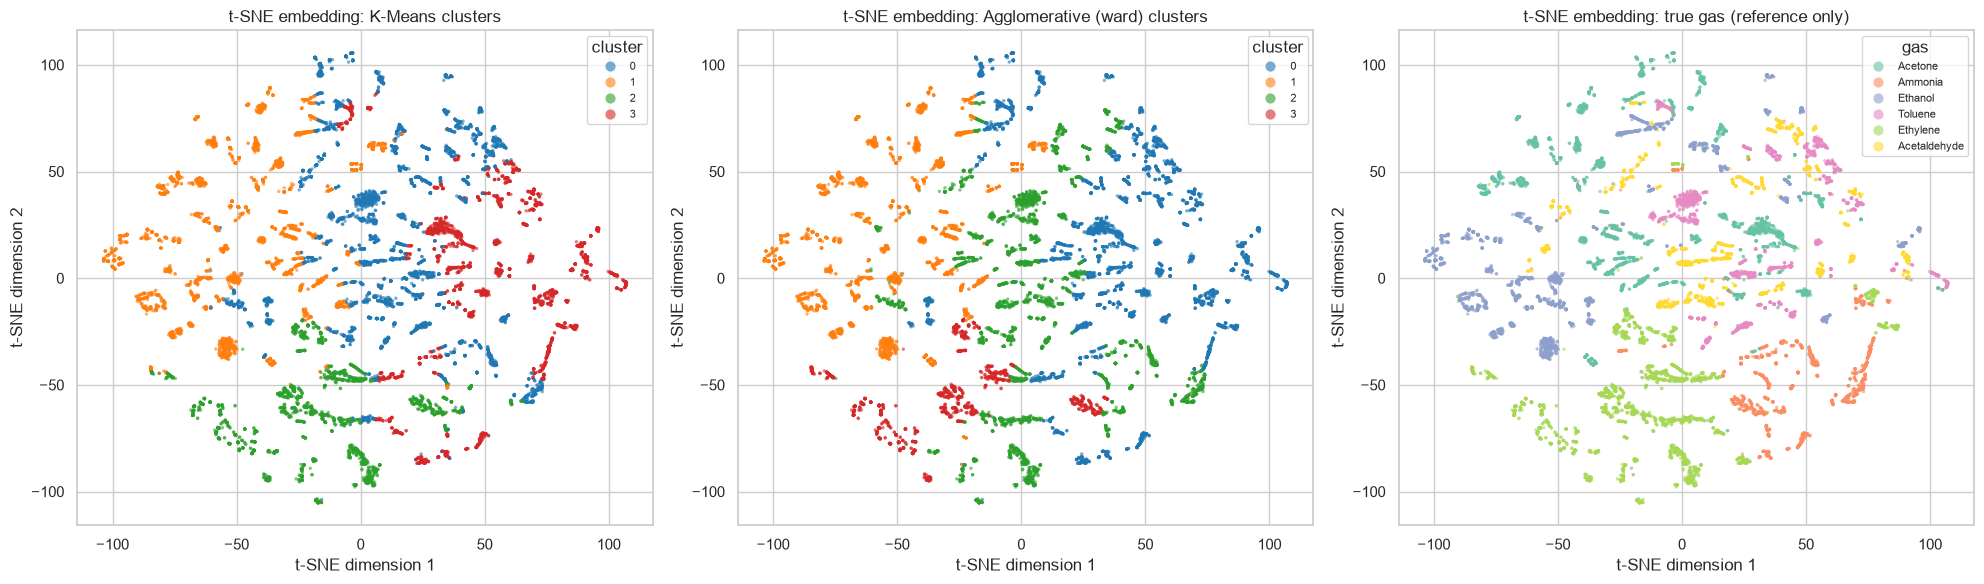

In [16]:
n_pc = 30
X_tsne = TSNE(n_components=2, perplexity=40, init='pca', learning_rate='auto', max_iter=1000,
              random_state=RANDOM_STATE).fit_transform(PCA(n_components=n_pc, random_state=RANDOM_STATE).fit_transform(X))

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, (name, lab) in zip(axes, labels.items()):
    scatter_2d(ax, X_tsne, lab, f't-SNE embedding: {name} clusters', 't-SNE dimension 1', 't-SNE dimension 2')
scatter_2d(axes[2], X_tsne, y_gas, 't-SNE embedding: true gas (reference only)',
           't-SNE dimension 1', 't-SNE dimension 2', palette='Set2')
save_fig('tsne_clusters.png')
plt.show()

**Observation.**
- t-SNE breaks the data into many small, tight islands rather than four or six large blobs. In the reference panel
  most islands are a **single gas**, so the local neighbourhood structure does follow the gas.
- Both algorithms colour whole islands consistently (islands are rarely split), but each cluster collects islands of
  several gases. The left islands (Ethanol, Acetone) form one cluster and the lower islands (Ethylene) another in both
  models.
- A likely reason for many islands per gas is the dataset's **sensor drift**: the same gas was measured over 36
  months, and the sensors' response shifted between batches, so one gas forms several separate groups.

## 7. Interpreting the clusters with the gas labels (after fitting)

The gas label was not used for fitting. Here it is compared with the clusters to see what the clusters *mean*:
- **Adjusted Rand Index (ARI)** — agreement between two partitions, corrected for chance (0 = random, 1 = identical);
- **Normalised Mutual Information (NMI)** — how much knowing the cluster tells you about the gas (0 ... 1);
- a **cross-tabulation** of cluster vs gas.

,ARI vs gas,NMI vs gas
K-Means,0.196,0.275
Agglomerative (ward),0.121,0.215


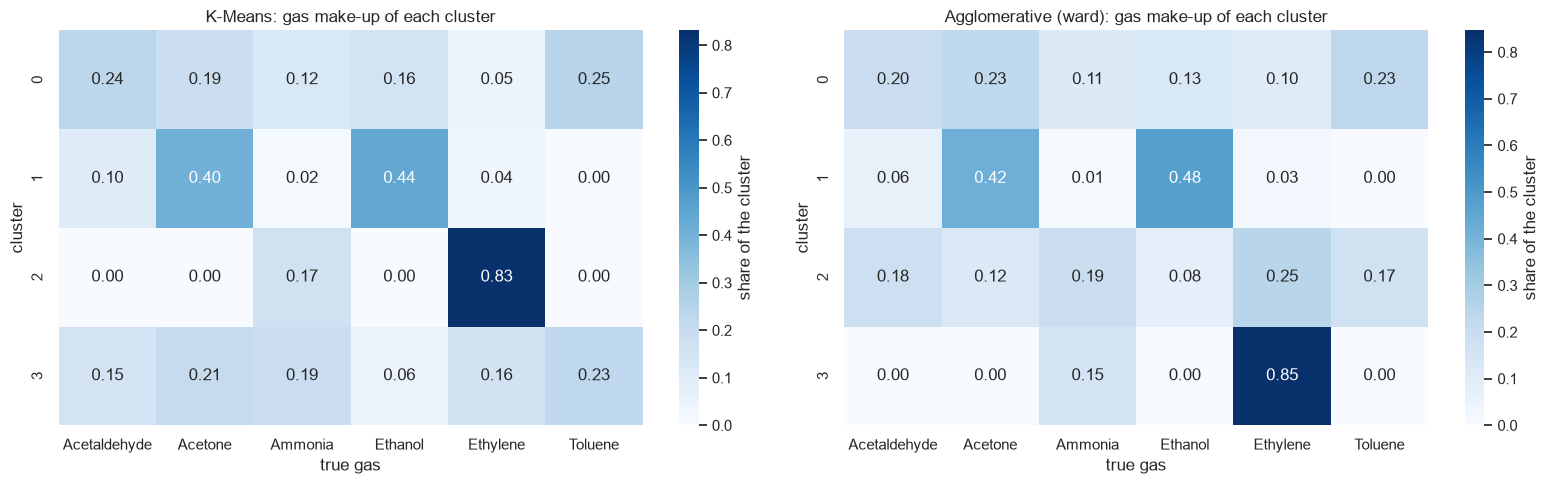

In [17]:
ext = pd.DataFrame({name: {'ARI vs gas': adjusted_rand_score(y_gas, lab),
                           'NMI vs gas': normalized_mutual_info_score(y_gas, lab)}
                    for name, lab in labels.items()}).T
display(ext.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (name, lab) in zip(axes, labels.items()):
    ct = pd.crosstab(pd.Series(lab, name='cluster'), y_gas.rename('gas'), normalize='index')
    sns.heatmap(ct, annot=True, fmt='.2f', cmap='Blues', cbar_kws={'label': 'share of the cluster'}, ax=ax)
    ax.set_title(f'{name}: gas make-up of each cluster')
    ax.set_xlabel('true gas')
    ax.set_ylabel('cluster')
save_fig('cluster_vs_gas_crosstab.png')
plt.show()

**Observation.**
- Agreement with the gas labels is low: ARI 0.196 (K-Means) and 0.121 (Ward), NMI 0.275 and 0.215. The clusters are
  not the six gases, which is expected with only 4 clusters and strong drift.
- They are still meaningful: one cluster is **83-85% Ethylene** in both models, and another is **Acetone + Ethanol**
  (84% K-Means, 90% Ward). The remaining clusters mix Acetaldehyde, Toluene and Ammonia, gases whose sensor responses
  are similar in this feature space.
- K-Means agrees with the gas labels more than Ward, in line with its better internal metrics.

In [18]:
summary = metrics_table.join(ext)
summary.to_csv(RESULTS_DIR / 'clustering_summary.csv')
display(summary.round(3))

,n_clusters,silhouette,davies_bouldin,calinski_harabasz,ARI vs gas,NMI vs gas
algorithm,,,,,,
K-Means,4.0,0.267,1.253,6673.565,0.196,0.275
Agglomerative (ward),4.0,0.202,1.378,5390.260,0.121,0.215


## 8. Summary (B2 + B3)

| Algorithm | k | Silhouette | Davies-Bouldin | Calinski-Harabasz | ARI vs gas |
|---|---|---|---|---|---|
| K-Means | 4 | **0.267** | **1.253** | **6,674** | **0.196** |
| Agglomerative (ward) | 4 | 0.202 | 1.378 | 5,390 | 0.121 |

- **B2:** the Elbow curve (k = 4) and the Ward dendrogram (natural cut at 4 clusters, strongest split at 2) agree on
  k. Silhouette, Davies-Bouldin and Calinski-Harabasz are reported for both algorithms and for all four linkages;
  single and average linkage look best on two metrics only because they produce one giant cluster.
- **B3:** PCA 2-D plots (77% of the variance) and t-SNE plots are shown for both algorithms, next to the true gas
  for reference.
- **K-Means** is the better clustering on every internal metric and agrees best with the gases. The clusters pick
  out an Ethylene group and an Acetone / Ethanol group; the other gases are mixed, largely because sensor drift
  spreads each gas over several regions.
- Saved: `results/clustering/clustering_metrics.csv`, `linkage_comparison.csv`, `clustering_summary.csv` and all
  plots (`kmeans_elbow_silhouette.png`, `hierarchical_dendrogram_ward.png`, `linkage_comparison.png`,
  `clustering_metrics_comparison.png`, `pca_clusters.png`, `tsne_clusters.png`, `cluster_vs_gas_crosstab.png`).